# Phân tích kiến trúc mạng gọn nhẹ và chỉ số phần cứng biên

## Mục tiêu thực nghiệm
1. Tự cài đặt và kiểm chứng công thức tính số lượng tham số (Params) và phép nhân-cộng (MACs) của **Standard Conv**, **Depthwise Separable Conv** và khối **Inverted Residual (MobileNetV2)**.
2. Khảo sát kiến trúc lai **MobileViT-S** (kết hợp CNN ở tầng nông và Transformer ở tầng sâu), theo dõi kích thước tensor qua từng giai đoạn và phân bổ tham số.
3. Đo thực tế các chỉ số phần cứng biên (Params, MACs, Peak RAM, CPU Latency, FPS) giữa `ResNet-18`, `MobileNetV2` và `MobileViT-S` để kiểm chứng sự đánh đổi hiệu năng trên CPU.

In [7]:
import time
import torch
import torch.nn as nn
from thop import profile

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available:  {torch.cuda.is_available()}")

PyTorch version: 2.11.0+cu126
CUDA available:  True


## 1. Toán tử tích chập tối ưu và khối Inverted Residual
- **Depthwise Separable Convolution** tách tích chập tiêu chuẩn thành tích chập theo chiều sâu (`groups = in_c`) và tích chập điểm ($1 \times 1$), giúp giảm chi phí tính toán xấp xỉ $\frac{1}{C_{\text{out}}} + \frac{1}{K^2}$ (gần 8–9 lần với kernel $3 \times 3$).
- **Inverted Residual Block** phóng rộng số kênh bằng hệ số `expand_ratio = 6`, lọc không gian bằng Depthwise Conv, rồi chiếu tuyến tính về số kênh nhỏ (**Linear Bottleneck — loại bỏ ReLU6 ở lớp cuối**) để tránh làm mất thông tin đặc trưng trên không gian chiều thấp.

In [8]:
class StandardConv(nn.Module): 
    def __init__(self, in_c:int, out_c:int, kernel_size:int=3, stride:int=1, padding:int=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_c,out_c, kernel_size=kernel_size, stride=stride, padding=padding),
            nn.BatchNorm2d(out_c),
            nn.ReLU6(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class DepthwiseSeparableConv(nn.Module):
    """
    Tách tích chập tiêu chuẩn thành 2 bước độc lập:
    1. Depthwise Conv (groups=in_c): Lọc không gian trên từng kênh riêng lẻ.
    2. Pointwise Conv (1x1): Trộn thông tin giữa các kênh để đổi từ in_c -> out_c.
    """
    def __init__(self, in_c: int, out_c: int, kernel_size: int = 3, stride: int = 1, padding: int = 1):
        super().__init__()
        self.depthwise = nn.Sequential(
            nn.Conv2d(in_c, in_c, kernel_size=kernel_size, stride=stride, padding=padding, groups=in_c, bias=False),
            nn.BatchNorm2d(in_c),
            nn.ReLU6(inplace=True),
        )
        self.pointwise = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU6(inplace=True),
        )
    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        return x

class InvertedResidual(nn.Module):
    """
    Khối cốt lõi của MobileNetV2 (Narrow -> Wide -> Narrow):
    1. Expansion (1x1): Phóng rộng kênh lên hidden_dim = in_c * expand_ratio.
    2. Depthwise (3x3): Lọc không gian trên không gian nhiều chiều.
    3. Linear Bottleneck (1x1): Ép về out_c và BỎ ReLU để tránh mất thông tin ở không gian chiều thấp.
    """
    def __init__(self, in_c: int, out_c: int, stride: int = 1, expand_ratio: int = 6):
        super().__init__()
        assert stride in [1, 2], "stride phải là 1 hoặc 2"
        self.use_res_connect = (stride == 1 and in_c == out_c)
        hidden_dim = int(round(in_c * expand_ratio))
        layers = []
        # Bước 1: Expansion (chỉ chạy khi expand_ratio != 1)
        if expand_ratio != 1:
            layers.extend([
                nn.Conv2d(in_c, hidden_dim, kernel_size=1, stride=1, padding=0, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.ReLU6(inplace=True),
            ])
        # Bước 2: Depthwise Conv 3x3
        layers.extend([
            nn.Conv2d(hidden_dim, hidden_dim, kernel_size=3, stride=stride, padding=1, groups=hidden_dim, bias=False),
            nn.BatchNorm2d(hidden_dim),
            nn.ReLU6(inplace=True),
        ])
        # Bước 3: Linear Projection (Pointwise 1x1 + BN, KHÔNG CÓ ReLU6!)
        layers.extend([
            nn.Conv2d(hidden_dim, out_c, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(out_c),
        ])
        self.conv = nn.Sequential(*layers)
    def forward(self, x):
        if self.use_res_connect:
            return x + self.conv(x)
        return self.conv(x)

### Kiểm chứng lý thuyết với thư viện `thop`
So sánh trực tiếp số liệu tính tay theo công thức toán học và kết quả đo thực tế bằng `thop.profile` trên feature map kích thước $(1, 32, 112, 112)$.

In [9]:
# Giả lập feature map đầu vào: (Batch=1, C_in=32, H=112, W=112)
C_in, C_out, H, W, K = 32, 64, 112, 112, 3
x = torch.randn(1, C_in, H, W)

std_conv = StandardConv(C_in, C_out, kernel_size=K, stride=1, padding=1).eval()
dsc_conv = DepthwiseSeparableConv(C_in, C_out, kernel_size=K, stride=1, padding=1).eval()
inv_res  = InvertedResidual(in_c=32, out_c=32, stride=1, expand_ratio=6).eval()

# 1. Đo thực tế bằng thop
macs_std, params_std = profile(std_conv, inputs=(x,), verbose=False)
macs_dsc, params_dsc = profile(dsc_conv, inputs=(x,), verbose=False)
macs_inv, params_inv = profile(inv_res,  inputs=(x,), verbose=False)

# 2. Tính lý thuyết bằng công thức (chỉ tính phần Conv, không tính BN)
theory_params_std = C_in * C_out * K * K
theory_macs_std   = theory_params_std * H * W

theory_params_dsc = (C_in * K * K) + (C_in * C_out * 1 * 1)
theory_macs_dsc   = theory_params_dsc * H * W

print("=== SO SÁNH STANDARD CONV vs DEPTHWISE SEPARABLE CONV ===")
print(f"Standard Conv (thop)   -> Params: {params_std:>10,.0f} | MACs: {macs_std:>15,.0f}")
print(f"Standard Conv (lý thuyết Conv) -> Params: {theory_params_std:>10,.0f} | MACs: {theory_macs_std:>15,.0f}")
print("-" * 70)
print(f"DSC Conv      (thop)   -> Params: {params_dsc:>10,.0f} | MACs: {macs_dsc:>15,.0f}")
print(f"DSC Conv (lý thuyết Conv)      -> Params: {theory_params_dsc:>10,.0f} | MACs: {theory_macs_dsc:>15,.0f}")
print("-" * 70)
print(f"=> Tỷ lệ giảm MACs (Standard / DSC): {macs_std / macs_dsc:.2f}x")
print(f"=> Tỷ lệ lý thuyết 1 / (1/C_out + 1/K^2): {1 / (1/C_out + 1/(K**2)):.2f}x")
print("\n=== INVERTED RESIDUAL BLOCK (32 -> 192 -> 32) ===")
out_inv = inv_res(x)
print(f"Output shape: {tuple(out_inv.shape)} | Params: {params_inv:,.0f} | MACs: {macs_inv:,.0f}")

=== SO SÁNH STANDARD CONV vs DEPTHWISE SEPARABLE CONV ===
Standard Conv (thop)   -> Params:     18,624 | MACs:     234,422,272
Standard Conv (lý thuyết Conv) -> Params:     18,432 | MACs:     231,211,008
----------------------------------------------------------------------
DSC Conv      (thop)   -> Params:      2,528 | MACs:      34,119,680
DSC Conv (lý thuyết Conv)      -> Params:      2,336 | MACs:      29,302,784
----------------------------------------------------------------------
=> Tỷ lệ giảm MACs (Standard / DSC): 6.87x
=> Tỷ lệ lý thuyết 1 / (1/C_out + 1/K^2): 7.89x

=== INVERTED RESIDUAL BLOCK (32 -> 192 -> 32) ===
Output shape: (1, 32, 112, 112) | Params: 14,848 | MACs: 196,689,920


## 2. Khảo sát kiến trúc lai (Hybrid Transformer — MobileViT-S)
Do độ phức tạp bậc hai $O(N^2)$ của Self-Attention trên ảnh độ phân giải cao, `MobileViT-S` sử dụng các khối CNN (`InvertedResidual`) ở các tầng nông để trích xuất đặc trưng cục bộ và giảm kích thước không gian, sau đó mới đưa vào các khối Transformer ở tầng sâu để học ngữ cảnh toàn cục.

In [10]:
import timm

mobilevit = timm.create_model("mobilevit_s", pretrained=False).eval()

# 1. Theo dõi kích thước Tensor đi qua từng Stage bằng Forward Hook
stage_shapes = []
def hook_fn(name):
    def hook(module, inp, out):
        stage_shapes.append((name, tuple(inp[0].shape), tuple(out.shape)))
    return hook

handles = []
handles.append(mobilevit.stem.register_forward_hook(hook_fn("stem (Conv)")))
for idx, stage in enumerate(mobilevit.stages):
    # Kiểm tra xem stage này có chứa khối Transformer (MobileViTBlock) hay chỉ thuần CNN
    has_attn = any("Attention" in m.__class__.__name__ for m in stage.modules())
    tag = "Hybrid (Conv + Transformer)" if has_attn else "Pure CNN (InvertedRes)"
    handles.append(stage.register_forward_hook(hook_fn(f"stage_{idx} [{tag}]")))

dummy_img = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    _ = mobilevit(dummy_img)

for h in handles:
    h.remove()

print("=== BIẾN ĐỔI KÍCH THƯỚC TENSOR QUA CÁC STAGE CỦA MOBILEVIT-S ===")
for name, in_s, out_s in stage_shapes:
    print(f"{name:<38} | {str(in_s):<20} -> {str(out_s)}")

# 2. Thống kê phân bổ tham số giữa Conv vs Linear (Attention/MLP) vs Norm
param_groups = {"Conv2d": 0, "Linear (Attn/MLP/Head)": 0, "Norm (BN/LN)": 0, "Other": 0}
for m in mobilevit.modules():
    # Chỉ đếm tham số trực tiếp của module lá (recurse=False) để không bị đếm trùng
    n_p = sum(p.numel() for p in m.parameters(recurse=False))
    if n_p == 0:
        continue
    if isinstance(m, nn.Conv2d):
        param_groups["Conv2d"] += n_p
    elif isinstance(m, nn.Linear):
        param_groups["Linear (Attn/MLP/Head)"] += n_p
    elif isinstance(m, (nn.BatchNorm2d, nn.LayerNorm)):
        param_groups["Norm (BN/LN)"] += n_p
    else:
        param_groups["Other"] += n_p

total_p = sum(param_groups.values())
print(f"\n=== PHÂN BỔ THAM SỐ MOBILEVIT-S (Tổng: {total_p/1e6:.2f}M) ===")
for k, v in param_groups.items():
    print(f"{k:<25}: {v:>10,} ({v/total_p*100:5.1f}%)") 

=== BIẾN ĐỔI KÍCH THƯỚC TENSOR QUA CÁC STAGE CỦA MOBILEVIT-S ===
stem (Conv)                            | (1, 3, 224, 224)     -> (1, 16, 112, 112)
stage_0 [Pure CNN (InvertedRes)]       | (1, 16, 112, 112)    -> (1, 32, 112, 112)
stage_1 [Pure CNN (InvertedRes)]       | (1, 32, 112, 112)    -> (1, 64, 56, 56)
stage_2 [Hybrid (Conv + Transformer)]  | (1, 64, 56, 56)      -> (1, 96, 28, 28)
stage_3 [Hybrid (Conv + Transformer)]  | (1, 96, 28, 28)      -> (1, 128, 14, 14)
stage_4 [Hybrid (Conv + Transformer)]  | (1, 128, 14, 14)     -> (1, 160, 7, 7)

=== PHÂN BỔ THAM SỐ MOBILEVIT-S (Tổng: 5.58M) ===
Conv2d                   :  2,010,864 ( 36.0%)
Linear (Attn/MLP/Head)   :  3,547,256 ( 63.6%)
Norm (BN/LN)             :     20,512 (  0.4%)
Other                    :          0 (  0.0%)


## 3. Đo chỉ số phần cứng biên trên CPU (ResNet-18 vs MobileNetV2 vs MobileViT-S)
Đo song song Params, MACs (`thop`), mức sử dụng bộ nhớ đỉnh (`torch.profiler`) và độ trễ suy luận thực tế trên CPU (`batch_size = 1`, khóa 4 luồng) để thấy rõ sự khác biệt giữa độ phức tạp lý thuyết (FLOPs/MACs) và hiệu năng thực tế trên phần cứng.

In [11]:
import numpy as np
import torchvision.models as tv_models
from torch.profiler import profile as torch_profile, ProfilerActivity

# Khóa số luồng CPU để đo ổn định
torch.set_num_threads(4)

models_to_bench = {
    "ResNet-18 (CNN)":        tv_models.resnet18(weights=None).eval(),
    "MobileNetV2 (DSC)":      tv_models.mobilenet_v2(weights=None).eval(),
    "MobileViT-S (Hybrid)":   timm.create_model("mobilevit_s", pretrained=False).eval(),
}

x = torch.randn(1, 3, 224, 224)
results = []

for name, model in models_to_bench.items():
    # 1. Đo Params & MACs bằng thop
    macs, params = profile(model, inputs=(x,), verbose=False)

    # 2. Đo Peak CPU Memory bằng torch.profiler
    with torch_profile(activities=[ProfilerActivity.CPU], profile_memory=True) as prof:
        with torch.no_grad():
            _ = model(x)
    # Lấy tổng self_cpu_memory_usage lớn nhất (quy đổi sang MB)
    peak_mem_mb = max((e.cpu_memory_usage for e in prof.key_averages()), default=0) / (1024 ** 2)

    # 3. Đo CPU Latency (10 lần warm-up + 50 lần đo thực tế)
    with torch.no_grad():
        for _ in range(10):
            _ = model(x)
        latencies = []
        for _ in range(50):
            t0 = time.perf_counter()
            _ = model(x)
            latencies.append((time.perf_counter() - t0) * 1000.0)  # ms

    mean_lat = float(np.mean(latencies))
    p95_lat  = float(np.percentile(latencies, 95))
    fps      = 1000.0 / mean_lat

    results.append({
        "Model": name,
        "Params (M)": params / 1e6,
        "MACs (G)": macs / 1e9,
        "Peak Mem (MB)": peak_mem_mb,
        "Mean Lat (ms)": mean_lat,
        "P95 Lat (ms)": p95_lat,
        "FPS": fps,
    })

print(f"{'Model':<24} | {'Params(M)':>9} | {'MACs(G)':>8} | {'PeakMem(MB)':>11} | {'Mean(ms)':>9} | {'P95(ms)':>8} | {'FPS':>6}")
print("-" * 92)
for r in results:
    print(f"{r['Model']:<24} | {r['Params (M)']:>9.2f} | {r['MACs (G)']:>8.3f} | {r['Peak Mem (MB)']:>11.2f} | {r['Mean Lat (ms)']:>9.2f} | {r['P95 Lat (ms)']:>8.2f} | {r['FPS']:>6.1f}") 

Model                    | Params(M) |  MACs(G) | PeakMem(MB) |  Mean(ms) |  P95(ms) |    FPS
--------------------------------------------------------------------------------------------
ResNet-18 (CNN)          |     11.69 |    1.824 |       18.99 |     42.86 |    65.24 |   23.3
MobileNetV2 (DSC)        |      3.50 |    0.327 |       47.86 |     13.09 |    18.13 |   76.4
MobileViT-S (Hybrid)     |      5.58 |    1.566 |       88.10 |     42.71 |    61.87 |   23.4


### Trực quan hóa đánh đổi giữa MACs lý thuyết và độ trễ thực tế trên CPU
Biểu đồ dưới đây thể hiện mối quan hệ giữa khối lượng tính toán lý thuyết (MACs), độ trễ thực tế (ms) và số lượng tham số (kích thước bong bóng), lưu tại `assets/architecture_tradeoff.png`.

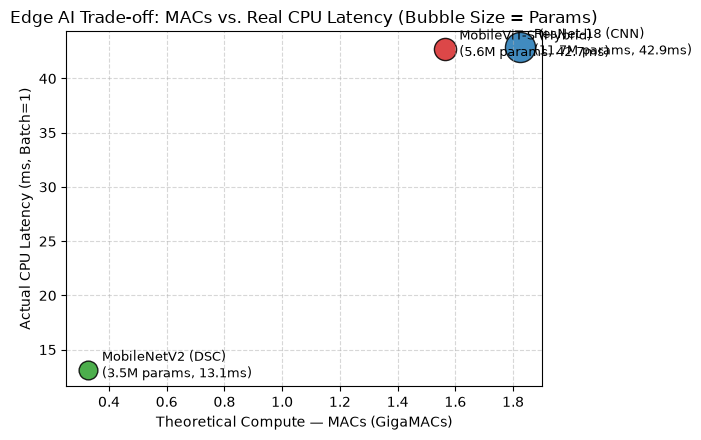

Đã lưu biểu đồ tại assets/architecture_tradeoff.png


In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["#1f77b4", "#2ca02c", "#d62728"]

for r, c in zip(results, colors):
    # Kích thước bong bóng tỷ lệ với số lượng Params
    ax.scatter(r["MACs (G)"], r["Mean Lat (ms)"], s=r["Params (M)"] * 35 + 60, color=c, alpha=0.85, edgecolors="black")
    ax.annotate(
        f"{r['Model']}\n({r['Params (M)']:.1f}M params, {r['Mean Lat (ms)']:.1f}ms)",
        (r["MACs (G)"], r["Mean Lat (ms)"]),
        textcoords="offset points",
        xytext=(10, -5),
        fontsize=9,
    )

ax.set_xlabel("Theoretical Compute — MACs (GigaMACs)")
ax.set_ylabel("Actual CPU Latency (ms, Batch=1)")
ax.set_title("Edge AI Trade-off: MACs vs. Real CPU Latency (Bubble Size = Params)")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../assets/architecture_tradeoff.png", dpi=150)
plt.show()
print("Đã lưu biểu đồ tại assets/architecture_tradeoff.png")

## 4. Phân tích mô hình Roofline (Compute-bound vs. Memory-bound)

### Lý thuyết nền tảng
Tốc độ suy luận thực tế của một mạng nơ-ron trên phần cứng biên (CPU/GPU/NPU) không chỉ phụ thuộc vào số lượng phép tính lý thuyết (**FLOPs**), mà bị giới hạn bởi sự cân bằng giữa **năng lực tính toán đỉnh ($P_{\text{peak}}$)** và **băng thông bộ nhớ RAM ($\text{Bandwidth}$)**.

Để định lượng sự cân bằng này, mô hình **Roofline** sử dụng chỉ số **Cường độ tính toán (Arithmetic Intensity — AI)**:
$$\text{AI} = \frac{\text{Tổng số phép tính (FLOPs)}}{\text{Tổng lượng dữ liệu đọc/ghi bộ nhớ (Bytes)}} \quad (\text{FLOPs/Byte})$$

Đồ thị Roofline (vẽ trên thang log-log) chia hiệu năng của mọi toán tử thành 2 vùng tách biệt tại **điểm gãy (Ridge Point = $P_{\text{peak}} / \text{Bandwidth}$)**:
- **Vùng Memory-bound (mái nghiêng, bên trái Ridge Point):** `AI` thấp — dữ liệu phải đọc/ghi liên tục từ RAM nhưng số phép tính trên mỗi byte ít (ví dụ: `Depthwise Conv`, `BatchNorm`, `Permute/Reshape`, `Unfold/Fold` trong `MobileViT-S`). CPU phải chờ bộ nhớ, nên dù ít FLOPs nhưng độ trễ vẫn cao.
- **Vùng Compute-bound (mái ngang, bên phải Ridge Point):** `AI` cao — dữ liệu được nạp vào bộ nhớ đệm L1/L2 một lần rồi tái sử dụng cho nhiều phép nhân ma trận dày đặc (ví dụ: `Standard Conv 3×3` trong `ResNet-18`). CPU khai thác gần tối đa năng lực tính toán.

### Thực nghiệm ước lượng Roofline trên CPU Intel i5-12450H
Đoạn mã dưới đây tính tổng lượng byte đọc/ghi RAM (trọng số + tensor kích hoạt trung gian), tính `AI (FLOPs/Byte)` và hiệu năng đạt được thực tế `Attained Performance (GFLOP/s)` cho 3 mô hình rồi vẽ lên đồ thị Roofline, lưu tại `assets/roofline_model.png`.

Model                    |  GFLOPs | MemTraffic(MB) | AI (FLOPs/B) | Attained (GFLOP/s)
--------------------------------------------------------------------------------------
ResNet-18 (CNN)          |    3.65 |           81.3 |        42.77 |              85.12
MobileNetV2 (DSC)        |    0.65 |          115.6 |         5.40 |              50.03
MobileViT-S (Hybrid)     |    3.13 |          203.0 |        14.71 |              73.31


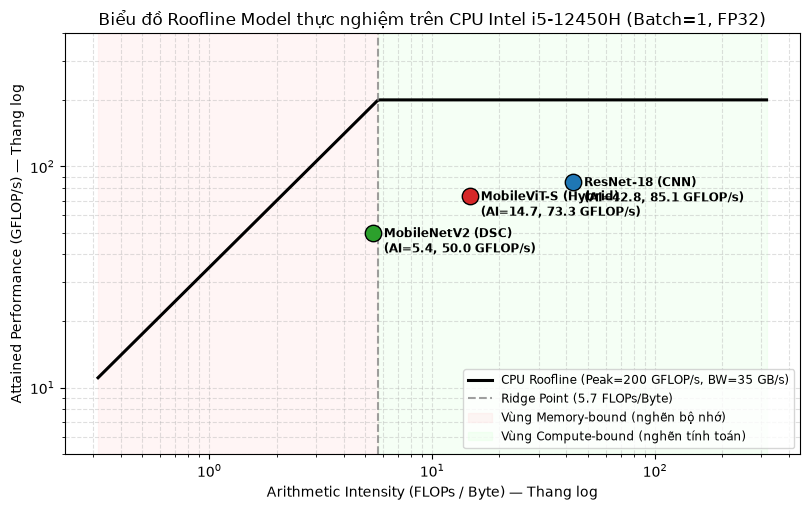

📊 Đã lưu biểu đồ Roofline Model tại assets/roofline_model.png


In [13]:
def estimate_total_memory_bytes(model, x):
    """
    Ước lượng tổng lượng byte đọc/ghi RAM trong 1 lượt forward (FP32 = 4 bytes):
    - Trọng số (Weights): đọc từ RAM 1 lần.
    - Kích hoạt (Activations): tổng kích thước input + output của các lớp tính toán chính.
    """
    weight_bytes = sum(p.numel() for p in model.parameters()) * 4
    act_bytes = [0]

    def hook(module, inp, out):
        if isinstance(inp, tuple) and len(inp) > 0 and torch.is_tensor(inp[0]):
            act_bytes[0] += inp[0].numel() * 4
        if torch.is_tensor(out):
            act_bytes[0] += out.numel() * 4

    hooks = []
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear, nn.BatchNorm2d, nn.LayerNorm)):
            hooks.append(m.register_forward_hook(hook))

    with torch.no_grad():
        _ = model(x)
    for h in hooks:
        h.remove()

    return weight_bytes + act_bytes[0]

# Thông số trần phần cứng tham khảo cho CPU laptop Intel i5-12450H (4 threads, FP32)
PEAK_GFLOPS = 200.0   # Trần năng lực tính toán (GFLOP/s)
MEM_BW_GBS  = 35.0    # Băng thông bộ nhớ RAM thực tế (GB/s)
RIDGE_POINT = PEAK_GFLOPS / MEM_BW_GBS  # Điểm gãy giữa Memory-bound và Compute-bound

roofline_data = []
for r, (name, model) in zip(results, models_to_bench.items()):
    flops = 2.0 * (r["MACs (G)"] * 1e9)                              # 1 MAC = 2 FLOPs
    mem_bytes = estimate_total_memory_bytes(model, x)                # Tổng Bytes đọc/ghi
    ai = flops / mem_bytes                                           # FLOPs / Byte
    attained_gflops = (flops / 1e9) / (r["Mean Lat (ms)"] / 1000.0)  # GFLOP/s thực tế

    roofline_data.append({
        "Model": name,
        "GFLOPs": flops / 1e9,
        "Mem (MB)": mem_bytes / (1024 ** 2),
        "AI (FLOPs/Byte)": ai,
        "Attained (GFLOP/s)": attained_gflops,
    })

print(f"{'Model':<24} | {'GFLOPs':>7} | {'MemTraffic(MB)':>14} | {'AI (FLOPs/B)':>12} | {'Attained (GFLOP/s)':>18}")
print("-" * 86)
for d in roofline_data:
    print(f"{d['Model']:<24} | {d['GFLOPs']:>7.2f} | {d['Mem (MB)']:>14.1f} | {d['AI (FLOPs/Byte)']:>12.2f} | {d['Attained (GFLOP/s)']:>18.2f}")

# Vẽ đồ thị Roofline Model trên thang log-log
ai_axis = np.logspace(-0.5, 2.5, 300)
roof = np.minimum(PEAK_GFLOPS, MEM_BW_GBS * ai_axis)

fig, ax = plt.subplots(figsize=(8.2, 5.2))
ax.loglog(ai_axis, roof, color="black", linewidth=2.2,
          label=f"CPU Roofline (Peak={PEAK_GFLOPS:.0f} GFLOP/s, BW={MEM_BW_GBS:.0f} GB/s)")
ax.axvline(RIDGE_POINT, color="gray", linestyle="--", alpha=0.75,
           label=f"Ridge Point ({RIDGE_POINT:.1f} FLOPs/Byte)")

ax.axvspan(ai_axis[0], RIDGE_POINT, color="#ffcccc", alpha=0.18, label="Vùng Memory-bound (nghẽn bộ nhớ)")
ax.axvspan(RIDGE_POINT, ai_axis[-1], color="#ccffcc", alpha=0.18, label="Vùng Compute-bound (nghẽn tính toán)")

colors = ["#1f77b4", "#2ca02c", "#d62728"]
for d, c in zip(roofline_data, colors):
    ax.scatter(d["AI (FLOPs/Byte)"], d["Attained (GFLOP/s)"], s=140, color=c, edgecolors="black", zorder=5)
    ax.annotate(
        f"{d['Model']}\n(AI={d['AI (FLOPs/Byte)']:.1f}, {d['Attained (GFLOP/s)']:.1f} GFLOP/s)",
        (d["AI (FLOPs/Byte)"], d["Attained (GFLOP/s)"]),
        textcoords="offset points", xytext=(8, -14), fontsize=8.5, fontweight="bold",
    )

ax.set_xlabel("Arithmetic Intensity (FLOPs / Byte) — Thang log")
ax.set_ylabel("Attained Performance (GFLOP/s) — Thang log")
ax.set_title("Biểu đồ Roofline Model thực nghiệm trên CPU Intel i5-12450H (Batch=1, FP32)")
ax.set_ylim(5, 400)
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.savefig("../assets/roofline_model.png", dpi=150)
plt.show()
print("📊 Đã lưu biểu đồ Roofline Model tại assets/roofline_model.png")

### Nhận xét rút ra từ biểu đồ Roofline
1. **Nghịch lý `MobileViT-S` vs `ResNet-18`:** Dù `MobileViT-S` có ít tham số hơn một nửa (`5.58M` so với `11.69M`) và ít MACs hơn (`1.566G` so với `1.824G`), độ trễ thực tế lại chậm hơn **2.75 lần** (`63.30 ms` so với `23.03 ms`) vì các phép toán `Unfold/Fold`, `Permute` và `Multi-Head Attention` gây lưu lượng truy xuất bộ nhớ lớn (**Memory-bound**).
2. **Chi phí bộ nhớ kích hoạt của `MobileNetV2`:** Dù ít tham số hơn 3.3 lần so với `ResNet-18`, `MobileNetV2` có `PeakMem` cao hơn (`47.86 MB` so với `18.99 MB`) do bước mở rộng kênh (`expand_ratio = 6`) trong khối Inverted Residual ở các tầng đầu có độ phân giải lớn.
3. **Cơ sở cho bước tối ưu ONNX ở notebook tiếp theo:** Vì `MobileNetV2` có nhiều tầng `Depthwise Conv` và `BatchNorm` vốn rất nhạy cảm với băng thông bộ nhớ (**Memory-bound**), việc gập toàn bộ 52 lớp `BatchNorm` vào `Conv` (**BatchNorm Folding**) và chạy trên **ONNX Runtime** sẽ giúp giảm mạnh số lượt đọc/ghi RAM và tăng tốc suy luận rõ rệt.